# Baseline Phishing Detector: Traditional (Innovatiana) Dataset
**CS 541 Project: The Impact of AI on Phishing Detection**

This notebook trains **Model 1**, the baseline trained only on traditionally written phishing/legitimate emails.
It uses TF-IDF features with Logistic Regression (primary baseline) and Linear SVM / Naive Bayes for comparison.
The fitted pipeline and the held-out test split are saved so they can later be evaluated on the AI-generated emails.

The dataset is a CSV with two columns, `text_combined` and `label` (0 = legitimate, 1 = phishing).

In [1]:
# !pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
import re, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

## 1. Config

In [3]:
DATA_PATH = "phishing_email.csv"   
TEXT_COL  = "text_combined"
LABEL_COL = "label"            # 1 = phishing, 0 = legitimate
TEST_SIZE = 0.20
MODEL_DIR = "."     # where to save artifacts

## 2. Load data

In [4]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape: (82486, 2)
Columns: ['text_combined', 'label']


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


In [5]:
# Auto-detect text and label columns if not set
def guess_cols(df):
    text_hints  = ["text", "body", "content", "message", "email"]
    label_hints = ["label", "type", "class", "category", "target", "phish"]
    obj_cols = [c for c in df.columns if df[c].dtype == object]
    # text column: matches hint, else longest average string length
    t = next((c for h in text_hints for c in obj_cols if h in c.lower()), None)
    if t is None and obj_cols:
        t = max(obj_cols, key=lambda c: df[c].astype(str).str.len().mean())
    l = next((c for h in label_hints for c in df.columns if h in c.lower() and c != t), None)
    return t, l

auto_t, auto_l = guess_cols(df)
TEXT_COL  = TEXT_COL  or auto_t
LABEL_COL = LABEL_COL or auto_l
print(f"Using TEXT_COL={TEXT_COL!r}, LABEL_COL={LABEL_COL!r}")
print(df[LABEL_COL].value_counts(dropna=False))

Using TEXT_COL='text_combined', LABEL_COL='label'
label
1    42891
0    39595
Name: count, dtype: int64


## 3. Clean and label
Labels are mapped to **1 = phishing, 0 = legitimate**. Check the printed mapping to be sure it is correct for your file.

In [6]:
data = df[[TEXT_COL, LABEL_COL]].copy()
data.columns = ["text", "label_raw"]

# Drop missing / empty / duplicate emails
before = len(data)
data["text"] = data["text"].astype(str).str.strip()
data = data[(data["text"].str.len() > 0) & (data["text"].str.lower() != "nan")]
data = data.dropna(subset=["label_raw"]).drop_duplicates(subset="text").reset_index(drop=True)
print(f"Removed {before - len(data)} empty/duplicate rows -> {len(data)} remain")

# Map labels to 0/1
def to_binary(v):
    s = str(v).strip().lower()
    if s in {"1", "1.0", "true"}: return 1
    if s in {"0", "0.0", "false"}: return 0
    if "phish" in s or "spam" in s or "malicious" in s or "fraud" in s: return 1
    if "safe" in s or "legit" in s or "ham" in s or "benign" in s: return 0
    return np.nan

data["label"] = data["label_raw"].map(to_binary)
print("\nLabel mapping used:")
print(data.groupby(["label_raw", "label"], dropna=False).size())
assert data["label"].notna().all(), "Unmapped labels found. Edit to_binary() above."
data["label"] = data["label"].astype(int)

Removed 409 empty/duplicate rows -> 82077 remain

Label mapping used:
label_raw  label
0          0        39233
1          1        42844
dtype: int64


         count        mean         std  min   25%    50%    75%       max
label                                                                    
0      39233.0  203.703897  481.196373  2.0  57.0  106.0  203.0   23359.0
1      42844.0  121.353072  594.758235  1.0  32.0   55.0  154.0  107710.0


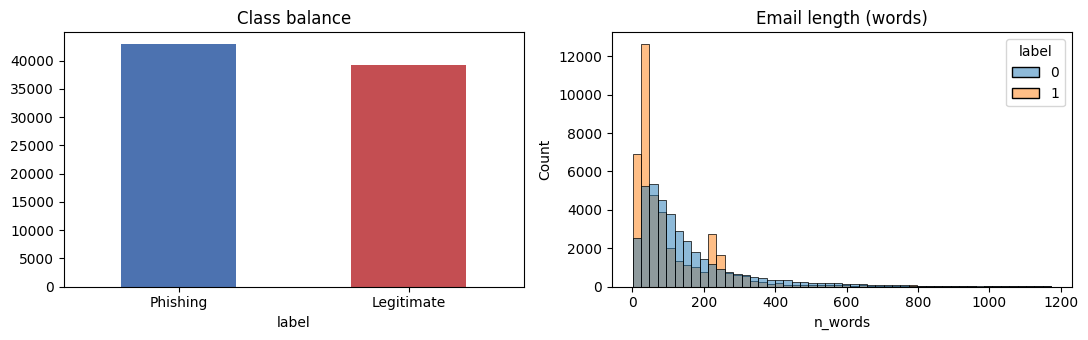

In [7]:
# Light text normalization (keeps URLs/numbers as tokens, since they carry signal)
def clean_text(t):
    t = t.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " urltoken ", t)
    t = re.sub(r"\S+@\S+", " emailtoken ", t)
    t = re.sub(r"<[^>]+>", " ", t)           # strip html tags
    t = re.sub(r"\s+", " ", t).strip()
    return t

data["clean"] = data["text"].map(clean_text)
data["n_words"] = data["clean"].str.split().str.len()
print(data.groupby("label")["n_words"].describe())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
data["label"].map({0: "Legitimate", 1: "Phishing"}).value_counts().plot.bar(ax=ax[0], color=["#4c72b0", "#c44e52"])
ax[0].set_title("Class balance"); ax[0].tick_params(axis="x", rotation=0)
sns.histplot(data=data[data.n_words < data.n_words.quantile(0.99)], x="n_words", hue="label", bins=50, ax=ax[1])
ax[1].set_title("Email length (words)")
plt.tight_layout(); plt.show()

## 4. Train/test split (stratified)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    data["clean"], data["label"], test_size=TEST_SIZE, stratify=data["label"], random_state=SEED)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print("Train phishing rate:", round(y_train.mean(), 3), "| Test phishing rate:", round(y_test.mean(), 3))

Train: 65661 | Test: 16416
Train phishing rate: 0.522 | Test phishing rate: 0.522


## 5. Models
TF-IDF is the shared vectorizer (word 1-2 grams). Logistic Regression is the primary baseline.

In [9]:
def make_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.95,
                           sublinear_tf=True, max_features=100_000, stop_words="english")

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, C=4.0, class_weight="balanced", random_state=SEED),
    "Linear SVM":          LinearSVC(C=1.0, class_weight="balanced", random_state=SEED),
    "Naive Bayes":         MultinomialNB(alpha=0.1),
}
pipelines = {name: Pipeline([("tfidf", make_tfidf()), ("clf", clf)]) for name, clf in models.items()}

rows = {}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "False Neg Rate": fn / (fn + tp),
        "False Pos Rate": fp / (fp + tn),
    }
results = pd.DataFrame(rows).T.round(4)
results

,Accuracy,Precision,Recall,F1,False Neg Rate,False Pos Rate
Logistic Regression,0.9896,0.9884,0.9917,0.9900,0.0083,0.0127
Linear SVM,0.9938,0.9924,0.9958,0.9941,0.0042,0.0083
Naive Bayes,0.9811,0.9952,0.9685,0.9817,0.0315,0.0051


## 6. Primary baseline: detailed evaluation (Logistic Regression)

              precision    recall  f1-score   support

  Legitimate     0.9909    0.9873    0.9891      7847
    Phishing     0.9884    0.9917    0.9900      8569

    accuracy                         0.9896     16416
   macro avg     0.9896    0.9895    0.9896     16416
weighted avg     0.9896    0.9896    0.9896     16416

ROC AUC: 0.9993


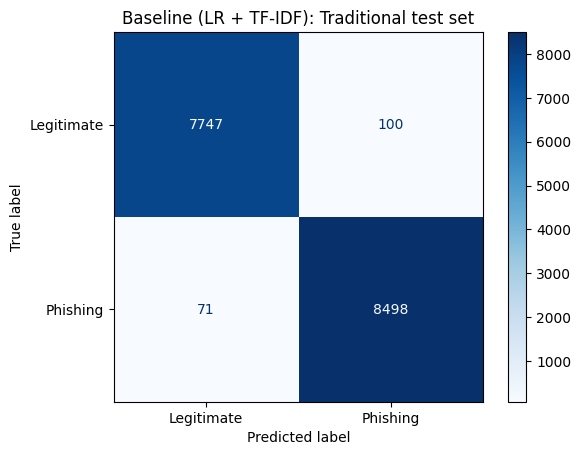

In [10]:
baseline = pipelines["Logistic Regression"]
y_pred = baseline.predict(X_test)
y_score = baseline.decision_function(X_test)

print(classification_report(y_test, y_pred, target_names=["Legitimate", "Phishing"], digits=4))
print("ROC AUC:", round(roc_auc_score(y_test, y_score), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Legitimate", "Phishing"], cmap="Blues")
plt.title("Baseline (LR + TF-IDF): Traditional test set"); plt.show()

In [11]:
# 5-fold cross-validation on the training set (stability check)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_f1 = cross_val_score(Pipeline([("tfidf", make_tfidf()),
                                  ("clf", LogisticRegression(max_iter=2000, C=4.0, class_weight="balanced"))]),
                        X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
print("CV F1 per fold:", cv_f1.round(4), "| mean:", cv_f1.mean().round(4), "+/-", cv_f1.std().round(4))

CV F1 per fold: [0.9891 0.9903 0.9916 0.9896 0.991 ] | mean: 0.9903 +/- 0.0009


## 7. Interpretability
The top-weighted words show which traditional "tells" the baseline relies on. These are likely to be the cues AI-generated phishing avoids.

In [12]:
vec = baseline.named_steps["tfidf"]; clf = baseline.named_steps["clf"]
feat = np.array(vec.get_feature_names_out()); coefs = clf.coef_[0]
top_phish = pd.DataFrame({"term": feat[np.argsort(coefs)[-25:][::-1]], "weight": np.sort(coefs)[-25:][::-1]})
top_legit = pd.DataFrame({"term": feat[np.argsort(coefs)[:25]], "weight": np.sort(coefs)[:25]})
display(pd.concat([top_phish.add_prefix("phish_"), top_legit.add_prefix("legit_")], axis=1))

,phish_term,phish_weight,legit_term,legit_weight
0,josemonkeyorg,8.279995,wrote,-16.520140
1,0300,7.772770,enron,-15.145348
2,life,7.268070,thanks,-12.122716
3,love,7.140518,vince,-8.063919
4,money,7.104931,opensuse,-8.035371
5,account,7.080520,university,-8.032933
6,2004,7.074234,im,-7.182927
7,com,6.887529,louise,-6.802742
8,click,6.883628,ierant,-6.686317
9,http,6.680111,pm,-6.613869


In [13]:
# Error analysis: look at missed phishing emails (false negatives)
fn_idx = X_test.index[(y_test == 1) & (y_pred == 0)]
print(f"{len(fn_idx)} missed phishing emails. Sample:\n")
for i in fn_idx[:5]:
    print("-", data.loc[i, "text"][:300].replace("\n", " "), "...\n")

71 missed phishing emails. Sample:

- hi ...

- software 3000 breakfast store fountainhead leaven q news blogs white papers downloads reviews prices go alerts newsletters rss feeds click enterprise news mozilla freezes seamonkey 04 20 pm automation bigger deal offshoring 03 33 pm time kill ...

- sci fi convention hi asked pass might interested large infinity convention cardiff july confirmed star wars dr star trek guests looks one largest events part uk seen time great fun site http www cf ac uk ccin main ents sffc infinity html aid children cancer guests include dave prowse darth vader col ...

- paul thomas postmastertopsitezus multipart message mime format _nextpart_000_000b_01c238c5a7241df0 contenttype textplain charsetusascii contenttransferencoding 8bit could please kind renew topsitesus directory listing thursday december 5 continue show millions users information renewing please go ht ...

- davida davidamiramaxcom hi steph found talent looking check wwwpiercebrosnanlookalikec

## 8. Save artifacts for Model 2 / cross-evaluation
The saved pipeline can be loaded later and evaluated directly on the AI-generated phishing test set.

In [14]:
joblib.dump(baseline, f"{MODEL_DIR}/baseline_tfidf_lr.joblib")
pd.DataFrame({"text": X_test, "label": y_test}).to_csv(f"{MODEL_DIR}/traditional_test_set.csv", index=False)
results.to_csv(f"{MODEL_DIR}/baseline_results.csv")
print("Saved: baseline_tfidf_lr.joblib, traditional_test_set.csv, baseline_results.csv")

# --- Later, for the generalization test on AI-generated emails ---
# model = joblib.load("baseline_tfidf_lr.joblib")
# ai = pd.read_csv("ai_generated_test_set.csv")          # columns: text, label
# preds = model.predict(ai["text"].map(clean_text))
# print(classification_report(ai["label"], preds, digits=4))

Saved: baseline_tfidf_lr.joblib, traditional_test_set.csv, baseline_results.csv
